In [1]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

import xgboost as xgb
import lightgbm as lgb

import joblib


In [2]:

df_master = pd.read_csv('Beijing_PM25_Combined_Master_78888.csv')

# Load the Training Ready Dataset
df = pd.read_csv('Beijing_PM25_Training_Ready_75896.csv')

print("Datasets loaded successfully!")

print("\nMaster Dataset Shape:", df_master.shape)
print("Training Dataset Shape:", df.shape)

print("\nTraining Dataset Preview:")
display(df.head())


Datasets loaded successfully!

Master Dataset Shape: (78888, 10)
Training Dataset Shape: (75896, 10)

Training Dataset Preview:


,No,year,month,day,hour,PM2.5,station,DEWP,TEMP,PRES
0,1,2010,1,2,0,129.0,US_Embassy,-16.0,-4.0,1020.0
1,2,2010,1,2,1,148.0,US_Embassy,-15.0,-4.0,1020.0
2,3,2010,1,2,2,159.0,US_Embassy,-11.0,-5.0,1021.0
3,4,2010,1,2,3,181.0,US_Embassy,-7.0,-5.0,1022.0
4,5,2010,1,2,4,138.0,US_Embassy,-7.0,-5.0,1022.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75896 entries, 0 to 75895
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       75896 non-null  int64  
 1   year     75896 non-null  int64  
 2   month    75896 non-null  int64  
 3   day      75896 non-null  int64  
 4   hour     75896 non-null  int64  
 5   PM2.5    75896 non-null  float64
 6   station  75896 non-null  str    
 7   DEWP     75896 non-null  float64
 8   TEMP     75896 non-null  float64
 9   PRES     75896 non-null  float64
dtypes: float64(4), int64(5), str(1)
memory usage: 6.6 MB


In [4]:
df.describe()

,No,year,month,day,hour,PM2.5,DEWP,TEMP,PRES
count,75896.000000,75896.000000,75896.000000,75896.000000,75896.000000,75896.000000,75896.000000,75896.000000,75896.000000
mean,37948.500000,2013.221263,6.497338,15.666913,11.497207,91.488356,2.432120,12.973201,1014.332414
std,21909.432352,1.852600,3.442532,8.785679,6.928758,88.082003,14.106205,11.840842,10.593134
min,1.000000,2010.000000,1.000000,1.000000,0.000000,0.000000,-40.000000,-19.000000,985.900000
25%,18974.750000,2012.000000,4.000000,8.000000,5.000000,26.000000,-9.000000,2.500000,1006.000000
50%,37948.500000,2013.000000,7.000000,16.000000,11.000000,66.000000,3.000000,14.000000,1014.000000
75%,56922.250000,2014.000000,10.000000,23.000000,18.000000,127.000000,15.400000,23.000000,1023.000000
max,75896.000000,2017.000000,12.000000,31.000000,23.000000,994.000000,28.500000,42.000000,1046.000000


In [5]:
# حساب عدد الصفوف المكررة
df.duplicated().sum()

np.int64(0)

In [6]:
df.isna().sum()

No         0
year       0
month      0
day        0
hour       0
PM2.5      0
station    0
DEWP       0
TEMP       0
PRES       0
dtype: int64

In [7]:

# ====================================================================
# 3. Dataset Validation
# ====================================================================

# Check Dataset Shape
print("Dataset Shape:", df.shape)

# Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Check Duplicate Records
print("\nDuplicate Records:", df.duplicated().sum())

# Check Monitoring Stations
print("\nMonitoring Stations:")
print(df['station'].value_counts())

# Check PM2.5 Statistics
print("\nPM2.5 Statistics:")
print(df['PM2.5'].describe())

# Check Date Range
df['Date'] = pd.to_datetime(
    df[['year', 'month', 'day', 'hour']]
)

print("\nDate Range:")
print("Start Date:", df['Date'].min())
print("End Date:", df['Date'].max())

# Check Duplicate Timestamps Within Each Station
duplicate_times = df.duplicated(
    subset=['station', 'Date']
).sum()

print("\nDuplicate Station Timestamps:", duplicate_times)

print("\nDataset validation completed!")


Dataset Shape: (75896, 10)

Missing Values:
No         0
year       0
month      0
day        0
hour       0
PM2.5      0
station    0
DEWP       0
TEMP       0
PRES       0
dtype: int64



Duplicate Records: 0

Monitoring Stations:
station
US_Embassy      41757
Aotizhongxin    34139
Name: count, dtype: int64

PM2.5 Statistics:
count    75896.000000
mean        91.488356
std         88.082003
min          0.000000
25%         26.000000
50%         66.000000
75%        127.000000
max        994.000000
Name: PM2.5, dtype: float64

Date Range:
Start Date: 2010-01-02 00:00:00
End Date: 2017-02-28 23:00:00

Duplicate Station Timestamps: 0

Dataset validation completed!


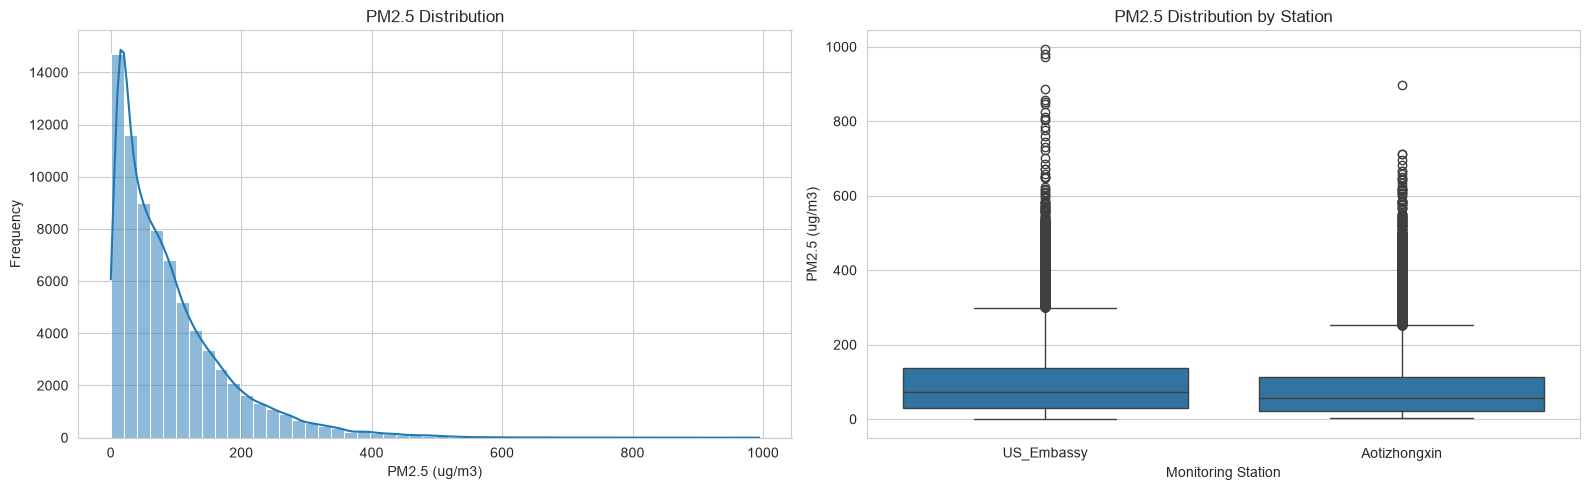

In [8]:

# ====================================================================
# 4. التحليل الاستكشافي للبيانات (EDA)
# ====================================================================

# تحديد نمط الرسوم البيانية
sns.set_style("whitegrid")

# إنشاء مساحة تحتوي على رسمين
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# رسم توزيع تركيز PM2.5
sns.histplot(
    data=df,
    x='PM2.5',
    bins=50,
    kde=True,
    ax=axes[0]
)

# إضافة العناوين والمحاور للرسم الأول
axes[0].set_title('PM2.5 Distribution')
axes[0].set_xlabel('PM2.5 (ug/m3)')
axes[0].set_ylabel('Frequency')

# مقارنة توزيع PM2.5 بين محطتي الرصد
sns.boxplot(
    data=df,
    x='station',
    y='PM2.5',
    ax=axes[1]
)

# إضافة العناوين والمحاور للرسم الثاني
axes[1].set_title('PM2.5 Distribution by Station')
axes[1].set_xlabel('Monitoring Station')
axes[1].set_ylabel('PM2.5 (ug/m3)')

# ضبط المسافات وعرض الرسوم البيانية
plt.tight_layout()
plt.show()


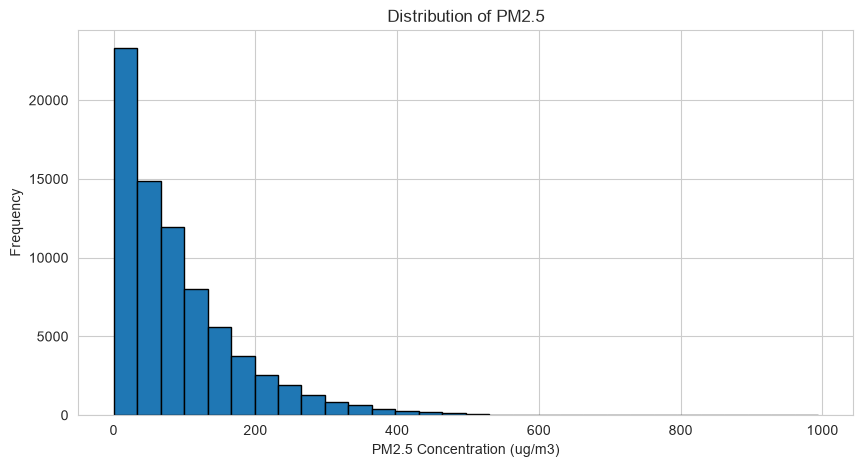

In [9]:

# ====================================================================
# 5. توزيع قيم تركيز الجسيمات الدقيقة PM2.5
# ====================================================================

# تحديد حجم الرسم البياني
plt.figure(figsize=(10, 5))

# رسم التوزيع التكراري لقيم PM2.5
plt.hist(df['PM2.5'], bins=30, edgecolor='black')

# إضافة عنوان الرسم وتسميات المحاور
plt.title('Distribution of PM2.5')
plt.xlabel('PM2.5 Concentration (ug/m3)')
plt.ylabel('Frequency')

# عرض الرسم البياني
plt.show()


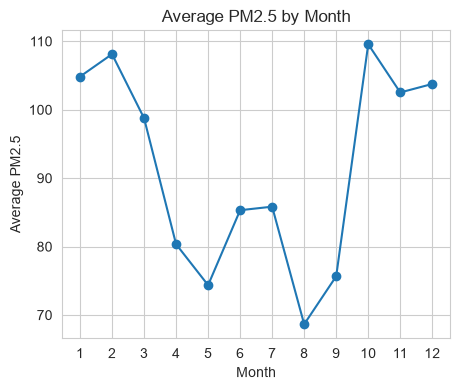

In [10]:
# متوسط التلوث لكل شهر مقارنه
monthly_avg = df.groupby('month')['PM2.5'].mean()
plt.figure(figsize=(5,4))
plt.plot(monthly_avg.index, monthly_avg.values, marker='o')
plt.title('Average PM2.5 by Month')
plt.xlabel('Month')
plt.ylabel('Average PM2.5')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

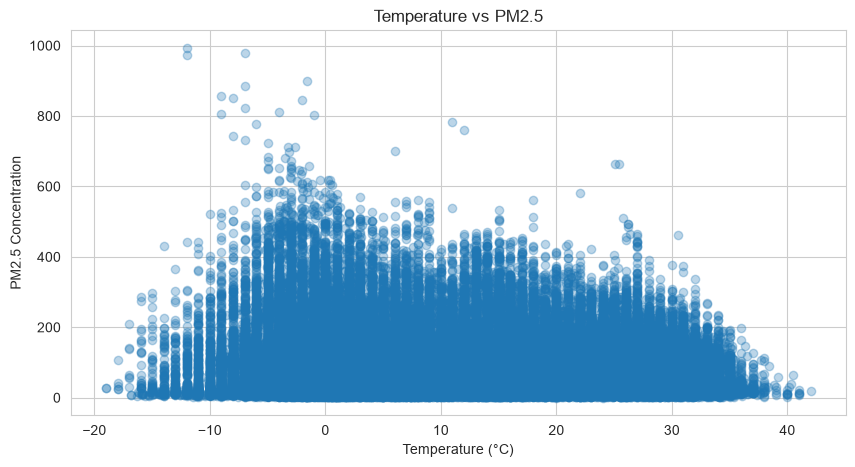

In [11]:
# العلاقة بين درجة الحرارة والتلوث
plt.figure(figsize=(10, 5))

plt.scatter(df['TEMP'], df['PM2.5'], alpha=0.3)

plt.title('Temperature vs PM2.5')
plt.xlabel('Temperature (°C)')
plt.ylabel('PM2.5 Concentration')

plt.grid(True)
plt.show()

In [12]:
df.isna().sum()

No         0
year       0
month      0
day        0
hour       0
PM2.5      0
station    0
DEWP       0
TEMP       0
PRES       0
Date       0
dtype: int64

In [13]:
df.shape

(75896, 11)

In [14]:


# ترتيب البيانات حسب المحطة ثم السنة والشهر واليوم والساعة
df = df.sort_values(
    ['station', 'year', 'month', 'day', 'hour']
).reset_index(drop=True)



In [15]:

# ====================================================================
# فصل المتغيرات المدخلة عن المتغير المستهدف
# ====================================================================

# تحديد المتغيرات المدخلة مع استبعاد رقم السجل والمتغير المستهدف
X = df.drop(columns=['No', 'PM2.5', 'Date'], errors='ignore')

# تحديد المتغير المستهدف وهو تركيز PM2.5
y = df['PM2.5']

# عرض أبعاد المتغيرات
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# عرض أسماء المتغيرات المدخلة
print("\nFeatures Columns:")
print(X.columns.tolist())


Features Shape: (75896, 8)
Target Shape: (75896,)

Features Columns:
['year', 'month', 'day', 'hour', 'station', 'DEWP', 'TEMP', 'PRES']


In [16]:

# ====================================================================
# التقسيم الزمني للبيانات بنسبة 80% تدريب و20% اختبار
# ====================================================================

# إنشاء قوائم لتجميع بيانات التدريب والاختبار
X_train_list = []
X_test_list = []

y_train_list = []
y_test_list = []

# تقسيم البيانات زمنياً لكل محطة على حدة
for station_name in X['station'].unique():

    # تحديد مواقع السجلات الخاصة بالمحطة الحالية
    station_indices = X.index[X['station'] == station_name]

    # حساب نقطة التقسيم بنسبة 80%
    split_index = int(len(station_indices) * 0.8)

    # تحديد سجلات التدريب والاختبار
    train_indices = station_indices[:split_index]
    test_indices = station_indices[split_index:]

    # إضافة بيانات التدريب
    X_train_list.append(X.loc[train_indices])
    y_train_list.append(y.loc[train_indices])

    # إضافة بيانات الاختبار
    X_test_list.append(X.loc[test_indices])
    y_test_list.append(y.loc[test_indices])

# دمج بيانات التدريب والاختبار لكل المحطات
X_train = pd.concat(X_train_list).sort_values(
    ['station', 'year', 'month', 'day', 'hour']
)

X_test = pd.concat(X_test_list).sort_values(
    ['station', 'year', 'month', 'day', 'hour']
)

y_train = pd.concat(y_train_list).loc[X_train.index]
y_test = pd.concat(y_test_list).loc[X_test.index]

# إعادة ترتيب الفهارس
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


In [17]:

# عرض أحجام بيانات التدريب والاختبار
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# عرض توزيع السجلات حسب المحطة
print("\nTraining Records by Station:")
print(X_train['station'].value_counts())

print("\nTesting Records by Station:")
print(X_test['station'].value_counts())


Training Data Shape: (60716, 8)
Testing Data Shape: (15180, 8)

Training Target Shape: (60716,)
Testing Target Shape: (15180,)

Training Records by Station:
station
US_Embassy      33405
Aotizhongxin    27311
Name: count, dtype: int64

Testing Records by Station:
station
US_Embassy      8352
Aotizhongxin    6828
Name: count, dtype: int64


In [18]:

# ====================================================================
# ترميز محطات الرصد باستخدام One-Hot Encoding
# ====================================================================

from sklearn.preprocessing import OneHotEncoder

# إنشاء أداة الترميز مع تجاهل الفئات غير المعروفة
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# تعلّم أسماء المحطات من بيانات التدريب فقط
X_train_station = encoder.fit_transform(X_train[['station']])

# تحويل بيانات الاختبار باستخدام نفس أداة الترميز
X_test_station = encoder.transform(X_test[['station']])

# استخراج أسماء الأعمدة الجديدة
station_columns = encoder.get_feature_names_out(['station'])

# إنشاء DataFrame للأعمدة الرقمية الجديدة
X_train_station = pd.DataFrame(
    X_train_station,
    columns=station_columns,
    index=X_train.index
)

X_test_station = pd.DataFrame(
    X_test_station,
    columns=station_columns,
    index=X_test.index
)

# حذف عمود المحطة النصي وإضافة الأعمدة الرقمية
X_train = pd.concat(
    [X_train.drop(columns=['station']), X_train_station],
    axis=1
)

X_test = pd.concat(
    [X_test.drop(columns=['station']), X_test_station],
    axis=1
)


In [19]:

# التحقق من نتيجة الترميز
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nNew Station Columns:")
print(station_columns.tolist())

print("\nRemaining Text Columns:")
print(
    X_train.select_dtypes(
        include=['object', 'str', 'category']
    ).columns.tolist()
)


X_train shape: (60716, 9)
X_test shape: (15180, 9)

New Station Columns:
['station_Aotizhongxin', 'station_US_Embassy']

Remaining Text Columns:
[]


In [20]:
# ====================================================================
# فحص أنواع بيانات المدخلات بعد المعالجة
# ====================================================================

# عرض أنواع بيانات الخصائص
print("أنواع بيانات التدريب:")
print(X_train.dtypes)

# فحص القيم المفقودة
print("\nعدد القيم المفقودة في التدريب:")
print(X_train.isna().sum().sum())

print("\nعدد القيم المفقودة في الاختبار:")
print(X_test.isna().sum().sum())

# فحص القيم اللانهائية
print("\nعدد القيم اللانهائية في التدريب:")
print(np.isinf(X_train.select_dtypes(include=np.number)).sum().sum())

print("\nعدد القيم اللانهائية في الاختبار:")
print(np.isinf(X_test.select_dtypes(include=np.number)).sum().sum())

print("\nتم فحص البيانات بنجاح!")

أنواع بيانات التدريب:
year                      int64
month                     int64
day                       int64
hour                      int64
DEWP                    float64
TEMP                    float64
PRES                    float64
station_Aotizhongxin    float64
station_US_Embassy      float64
dtype: object

عدد القيم المفقودة في التدريب:
0

عدد القيم المفقودة في الاختبار:
0

عدد القيم اللانهائية في التدريب:
0

عدد القيم اللانهائية في الاختبار:
0

تم فحص البيانات بنجاح!


In [21]:
# ====================================================================
# إنشاء نموذج XGBoost للتنبؤ بتركيز PM2.5
# ====================================================================

# إنشاء نموذج XGBoost بإعدادات التدريب المحددة
xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_alpha=0.1,
    reg_lambda=1,
    eval_metric='rmse',
    random_state=42,
    n_jobs=-1
)

# التأكد من إعداد النموذج
print("تم إعداد نموذج XGBoost بنجاح!")

تم إعداد نموذج XGBoost بنجاح!


In [22]:
# ====================================================================
# تدريب نموذج XGBoost وإجراء التنبؤ
# ====================================================================

# تدريب النموذج باستخدام بيانات التدريب
xgb_model.fit(X_train, y_train)

# print("تم تدريب النموذج بنجاح!")


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [23]:

# إجراء التنبؤ على بيانات التدريب
train_pred = xgb_model.predict(X_train)

# إجراء التنبؤ على بيانات الاختبار
test_pred = xgb_model.predict(X_test)

# print("\nتم إجراء التنبؤ على بيانات التدريب والاختبار بنجاح!")

In [24]:
# ====================================================================
# تقييم أداء نموذج XGBoost باستخدام مقاييس Regression
# ====================================================================

# حساب متوسط الخطأ المطلق
train_mae = mean_absolute_error(y_train, train_pred)
test_mae = mean_absolute_error(y_test, test_pred)

# حساب الجذر التربيعي لمتوسط مربعات الأخطاء
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

# حساب معامل التحديد
train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)


In [25]:

# عرض نتائج تقييم النموذج
print("Model Performance - XGBoost")
print("============================")

print(f"Train MAE: {train_mae:.2f}")
print(f"Test MAE: {test_mae:.2f}")

print(f"Train RMSE: {train_rmse:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")

print(f"Train R²: {train_r2:.2f}")
print(f"Test R²: {test_r2:.2f}")

Model Performance - XGBoost
Train MAE: 36.39
Test MAE: 42.95
Train RMSE: 52.24
Test RMSE: 61.62
Train R²: 0.64
Test R²: 0.53


In [26]:
# ====================================================================
# مقارنة القيم الحقيقية والمتوقعة باستخدام XGBoost
# ====================================================================

# التنبؤ باستخدام نموذج XGBoost على بيانات الاختبار
xgb_pred = xgb_model.predict(X_test)

# إنشاء جدول يحتوي على القيم الحقيقية والمتوقعة
comparison = pd.DataFrame({
    "Actual PM2.5": y_test.values,
    "Predicted PM2.5": xgb_pred
})

# حساب الفرق بين القيم الحقيقية والمتوقعة
comparison["Error"] = (
    comparison["Actual PM2.5"] -
    comparison["Predicted PM2.5"]
)

# حساب القيمة المطلقة للخطأ
comparison["Absolute Error"] = comparison["Error"].abs()

# عرض أول 10 نتائج
print("Actual vs Predicted PM2.5:")
display(comparison.head(10))

# عرض متوسط الخطأ المطلق
print("\nMean Absolute Error:")
print(round(comparison["Absolute Error"].mean(), 2))

Actual vs Predicted PM2.5:


,Actual PM2.5,Predicted PM2.5,Error,Absolute Error
0,22.0,20.505230,1.494770,1.494770
1,22.0,36.630383,-14.630383,14.630383
2,37.0,42.665356,-5.665356,5.665356
3,33.0,44.544537,-11.544537,11.544537
4,36.0,52.883762,-16.883762,16.883762
5,37.0,45.409744,-8.409744,8.409744
6,42.0,48.412220,-6.412220,6.412220
7,24.0,51.167461,-27.167461,27.167461
8,34.0,44.670971,-10.670971,10.670971
9,32.0,54.760063,-22.760063,22.760063



Mean Absolute Error:
42.95


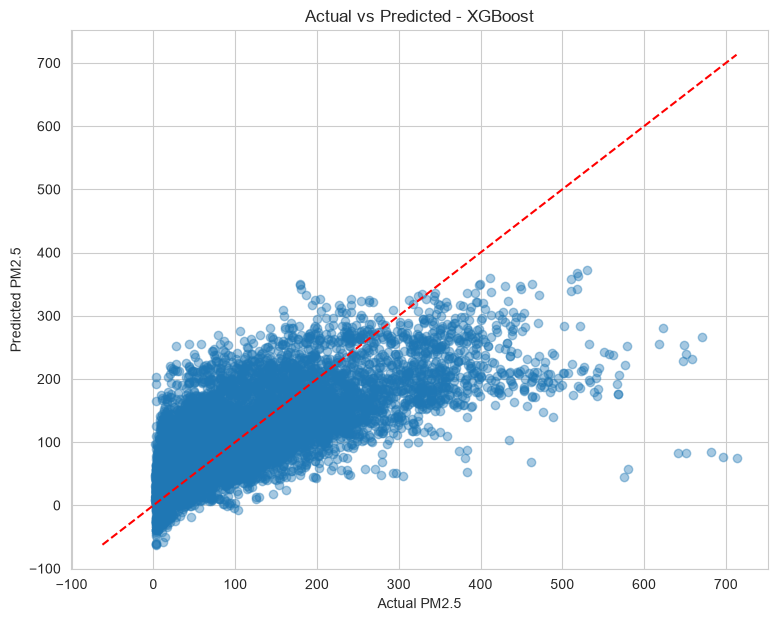

In [27]:
# رسم مقارنة القيم الحقيقية والمتوقعة
plt.figure(figsize=(9, 7))

plt.scatter(y_test, xgb_pred, alpha=0.4)

# خط التوقع المثالي
min_value = min(y_test.min(), xgb_pred.min())
max_value = max(y_test.max(), xgb_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("Actual vs Predicted - XGBoost")
plt.grid(True)
plt.show()

In [28]:
# الحصول على درجات أهمية المتغيرات من نموذج XGBoost
feature_importance = xgb_model.feature_importances_

# إنشاء جدول لأهمية المتغيرات
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
})

# ترتيب المتغيرات من الأكثر أهمية إلى الأقل
feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)

# عرض الجدول
print(feature_importance_df)

                Feature  Importance
4                  DEWP    0.222853
5                  TEMP    0.185569
1                 month    0.177713
7  station_Aotizhongxin    0.100016
8    station_US_Embassy    0.077454
2                   day    0.071141
6                  PRES    0.068746
0                  year    0.061726
3                  hour    0.034782


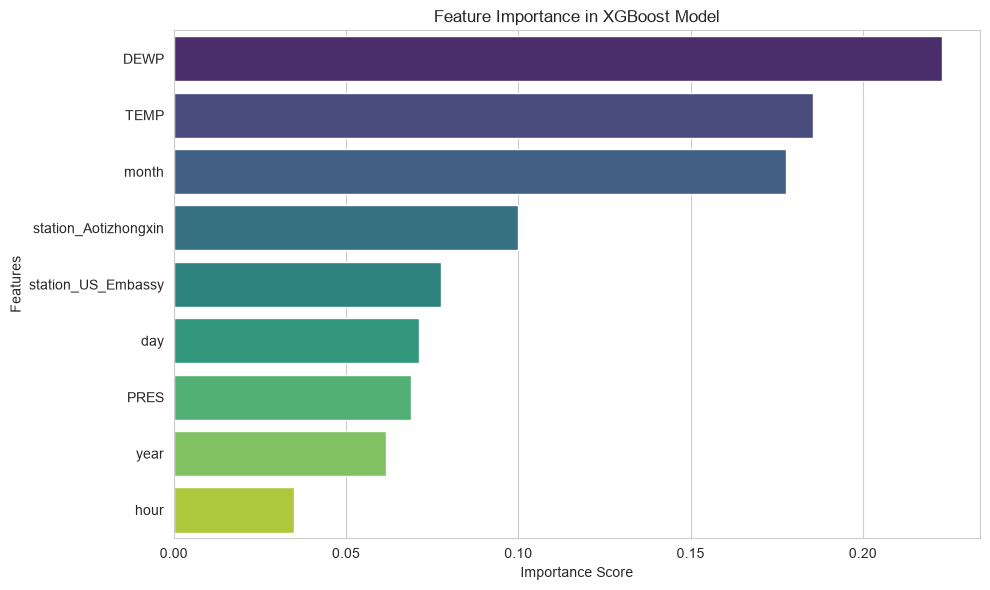

In [29]:
# رسم أهمية المتغيرات
plt.figure(figsize=(10, 6))

sns.barplot(
    x=feature_importance_df['Importance'],
    y=feature_importance_df['Feature'],
    hue=feature_importance_df['Feature'],
    palette='viridis',
    legend=False
)

plt.title("Feature Importance in XGBoost Model")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [30]:
# ====================================================================
# البحث عن أفضل إعدادات نموذج XGBoost
# ====================================================================

# استيراد أدوات البحث والتقسيم الزمني
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import TimeSeriesSplit

# تحديد الإعدادات التي سيجربها النموذج
param_dist = {
    'n_estimators': [100, 300, 500, 1000],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 5, 10],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [1, 5, 10]
}

# إنشاء تقسيم زمني للبيانات
tscv = TimeSeriesSplit(n_splits=3)

# إنشاء عملية البحث عن أفضل الإعدادات
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    n_iter=15,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# البحث باستخدام بيانات التدريب فقط
random_search.fit(X_train, y_train)

# print("تم الانتهاء من البحث عن أفضل إعدادات XGBoost بنجاح!")

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.6, 0.8, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a be

In [31]:
# ====================================================================
# عرض أفضل إعدادات نموذج XGBoost
# ====================================================================

# عرض أفضل الإعدادات التي وجدها البحث
print("Best Parameters:")
print(random_search.best_params_)

# عرض أفضل RMSE أثناء التحقق المتقاطع
print("\nBest Cross-Validation RMSE:")
print(round(-random_search.best_score_, 2))

Best Parameters:
{'subsample': 0.8, 'reg_lambda': 10, 'reg_alpha': 0.5, 'n_estimators': 1000, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.8}

Best Cross-Validation RMSE:
70.19


In [32]:
# ====================================================================
# تقييم أفضل نموذج XGBoost بعد تحسين الإعدادات
# ====================================================================

# استخراج أفضل نموذج من عملية البحث
best_xgb_model = random_search.best_estimator_

# إجراء التنبؤ على بيانات الاختبار
best_xgb_pred = best_xgb_model.predict(X_test)

# استيراد مقاييس التقييم
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# حساب مقاييس الأداء
mae = mean_absolute_error(y_test, best_xgb_pred)
rmse = np.sqrt(mean_squared_error(y_test, best_xgb_pred))
r2 = r2_score(y_test, best_xgb_pred)

# عرض نتائج النموذج المحسن
print("Optimized XGBoost Results")
print("=========================")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Optimized XGBoost Results
MAE: 43.79
RMSE: 62.91
R2 Score: 0.5152


In [33]:
# ====================================================================
# مقارنة نموذج XGBoost الأصلي والمحسّن على بيانات الاختبار
# ====================================================================

# إجراء التنبؤ باستخدام النموذج الأصلي
xgb_original_pred = xgb_model.predict(X_test)

# إجراء التنبؤ باستخدام النموذج المحسّن
xgb_optimized_pred = best_xgb_model.predict(X_test)

# إنشاء جدول مقارنة النماذج
model_comparison = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "MAE": mean_absolute_error(y_test, xgb_original_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, xgb_original_pred)),
        "R2": r2_score(y_test, xgb_original_pred)
    },
    {
        "Model": "Optimized XGBoost",
        "MAE": mean_absolute_error(y_test, xgb_optimized_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, xgb_optimized_pred)),
        "R2": r2_score(y_test, xgb_optimized_pred)
    }
])

# تقريب النتائج إلى أربع خانات عشرية
model_comparison = model_comparison.round(4)

# عرض جدول المقارنة
display(model_comparison)

# تحديد النموذج الأفضل بناءً على أقل RMSE
best_row = model_comparison.loc[
    model_comparison["RMSE"].idxmin()
]

# عرض اسم النموذج الأفضل
print("\nSelected Model:", best_row["Model"])

,Model,MAE,RMSE,R2
0,Original XGBoost,42.9502,61.6209,0.5348
1,Optimized XGBoost,43.7903,62.9065,0.5152



Selected Model: Original XGBoost


In [34]:
# ====================================================================
# حفظ نموذج XGBoost الأصلي وأدوات تجهيز البيانات
# ====================================================================

import joblib

# حفظ نموذج XGBoost الأصلي باعتباره الأفضل حتى الآن
joblib.dump(xgb_model, "best_pm25_model.pkl")

# حفظ أسماء الأعمدة المستخدمة أثناء التدريب وبنفس الترتيب
joblib.dump(list(X_train.columns), "pm25_feature_columns.pkl")

# حفظ أداة ترميز المحطات OneHotEncoder
joblib.dump(encoder, "pm25_encoder.pkl")

print("تم حفظ النموذج الأصلي وأدوات تجهيز البيانات بنجاح!")

تم حفظ النموذج الأصلي وأدوات تجهيز البيانات بنجاح!


In [35]:
# ====================================================================
# إعداد نموذج LightGBM للانحدار
# ====================================================================

from lightgbm import LGBMRegressor

# تحديد المعاملات الأساسية لنموذج LightGBM
hyper_params = {
    'objective': 'regression',
    'n_estimators': 500,
    'learning_rate': 0.05,
    'max_depth': 6,
    'num_leaves': 50,
    'colsample_bytree': 0.9,
    'subsample': 0.7,
    'subsample_freq': 10,
    'reg_lambda': 1,
    'verbosity': -1,
    'random_state': 42,
    'n_jobs': -1
}

# إنشاء نموذج LightGBM باستخدام المعاملات المحددة
lgb_model = LGBMRegressor(**hyper_params)

print("تم إعداد نموذج LightGBM بنجاح!")


تم إعداد نموذج LightGBM بنجاح!


In [36]:
# إنشاء نموذج LightGBM باستخدام المعاملات المحددة
lgbm_model = LGBMRegressor(**hyper_params)

# print("تم إنشاء نموذج LightGBM بنجاح!")

In [37]:
# ====================================================================
# تدريب نموذج LightGBM
# ====================================================================

# تدريب النموذج باستخدام بيانات التدريب
lgbm_model.fit(X_train, y_train)

# print("تم تدريب نموذج LightGBM للانحدار بنجاح!")

,num_leaves,50
,max_depth,6
,learning_rate,0.05
,n_estimators,500
,objective,'regression'
,subsample,0.7
,subsample_freq,10
,colsample_bytree,0.9
,reg_lambda,1
,random_state,42
,n_jobs,-1


In [38]:
# التنبؤ بتركيز PM2.5 باستخدام بيانات الاختبار
lgbm_pred = lgbm_model.predict(X_test)

# print("تم إنشاء التنبؤات بنجاح!")

In [39]:
# ====================================================================
# تحديد إعدادات نموذج Random Forest للانحدار
# ====================================================================

rf_params = {
    'n_estimators': 200,
    'max_depth': 16,
    'min_samples_split': 10,
    'min_samples_leaf': 4,
    'max_features': 'sqrt',
    'random_state': 42,
    'n_jobs': -1
}



In [40]:
# ====================================================================
# إنشاء نموذج Random Forest للانحدار
# ====================================================================

# استيراد نموذج Random Forest للانحدار
from sklearn.ensemble import RandomForestRegressor

# إنشاء النموذج باستخدام المعاملات المحددة مسبقاً
rf_model = RandomForestRegressor(**rf_params)



In [41]:
# ====================================================================
# تدريب نموذج Random Forest
# ====================================================================

# تدريب النموذج باستخدام بيانات التدريب
rf_model.fit(X_train, y_train)



,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",16
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,

In [42]:
# ====================================================================
# التنبؤ بقيم PM2.5 باستخدام بيانات الاختبار
# ====================================================================

rf_pred = rf_model.predict(X_test)



In [43]:
# ====================================================================
# مقارنة أداء نماذج Regression الأربعة
# ====================================================================

# تجميع التنبؤات الخاصة بجميع النماذج
models_predictions = {
    "Original XGBoost": xgb_pred,
    "Optimized XGBoost": best_xgb_pred,
    "LightGBM": lgbm_pred,
    "Random Forest": rf_pred
}

# إنشاء قائمة لتخزين نتائج التقييم
results = []

# حساب مقاييس الأداء لكل نموذج
for model_name, predictions in models_predictions.items():

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

# تحويل النتائج إلى DataFrame
model_comparison = pd.DataFrame(results)

# ترتيب النماذج حسب أقل قيمة RMSE
model_comparison = model_comparison.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

# عرض جدول مقارنة النماذج
display(model_comparison.round(4))

# تحديد النموذج الأفضل وفق أقل قيمة RMSE
selected_model_name = model_comparison.loc[0, "Model"]

print("\nBest Model based on Test RMSE:", selected_model_name)

,Model,MAE,RMSE,R2
0,Original XGBoost,42.9502,61.6209,0.5348
1,LightGBM,43.5854,62.3120,0.5243
2,Optimized XGBoost,43.7903,62.9065,0.5152
3,Random Forest,46.5711,65.0758,0.4812



Best Model based on Test RMSE: Original XGBoost


In [44]:
# ====================================================================
# حفظ نماذج التنبؤ وتجهيزات البيانات
# ====================================================================

# حفظ النماذج الأربعة
joblib.dump(xgb_model, "xgboost_pm25_model.pkl")
joblib.dump(best_xgb_model, "optimized_xgboost_pm25_model.pkl")
joblib.dump(lgbm_model, "lightgbm_pm25_model.pkl")
joblib.dump(rf_model, "random_forest_pm25_model.pkl")

# تحديد كائن النموذج المختار
models = {
    "Original XGBoost": xgb_model,
    "Optimized XGBoost": best_xgb_model,
    "LightGBM": lgbm_model,
    "Random Forest": rf_model
}

# استرجاع النموذج الذي حقق أقل RMSE
final_model = models[selected_model_name]

# حفظ النموذج النهائي المختار
joblib.dump(final_model, "best_pm25_model.pkl")

# حفظ أسماء وترتيب الخصائص المستخدمة في التدريب
joblib.dump(list(X_train.columns), "pm25_feature_columns.pkl")

# حفظ أداة ترميز المحطات
joblib.dump(encoder, "pm25_encoder.pkl")

# حفظ القيم الوسيطة للطقس إذا كانت معرفة
if "weather_medians" in globals():
    joblib.dump(weather_medians, "pm25_weather_medians.pkl")
    print("تم حفظ القيم الوسيطة للطقس بنجاح!")
else:
    print("لم يتم حفظ القيم الوسيطة: المتغير weather_medians غير معرّف.")

print("\nتم حفظ النماذج وتجهيزات البيانات بنجاح!")
print("النموذج النهائي المختار:", selected_model_name)

لم يتم حفظ القيم الوسيطة: المتغير weather_medians غير معرّف.

تم حفظ النماذج وتجهيزات البيانات بنجاح!
النموذج النهائي المختار: Original XGBoost


In [45]:
# حفظ نموذج XGBoost الأصلي
joblib.dump(xgb_model, "xgboost_pm25_model.pkl")



['xgboost_pm25_model.pkl']

In [46]:
# حفظ نموذج LightGBM
joblib.dump(lgbm_model, "lightgbm_pm25_model.pkl")



['lightgbm_pm25_model.pkl']

In [47]:
# حفظ نموذج Random Forest
joblib.dump(rf_model, "random_forest_pm25_model.pkl")



['random_forest_pm25_model.pkl']

In [48]:
# حفظ أداة ترميز محطات الرصد
joblib.dump(encoder, "pm25_encoder.pkl")



['pm25_encoder.pkl']

In [49]:
# ====================================================================
# اختبار تحميل النموذج النهائي والتحقق من عمله
# ====================================================================

# تحميل النموذج النهائي المحفوظ
loaded_model = joblib.load("best_pm25_model.pkl")

# إجراء التنبؤ باستخدام أول خمس عينات من بيانات الاختبار
sample_prediction = loaded_model.predict(X_test.iloc[:5])

# عرض نتائج التنبؤ
print("أول خمس تنبؤات بعد تحميل النموذج:")
print(sample_prediction)

print("\nتم تحميل النموذج واختباره بنجاح!")

أول خمس تنبؤات بعد تحميل النموذج:
[20.50523  36.630383 42.665356 44.544537 52.883762]

تم تحميل النموذج واختباره بنجاح!


In [50]:
# ====================================================================
# حفظ أسماء الأعمدة المستخدمة أثناء تدريب النموذج
# ====================================================================

# استخراج أسماء الخصائص وترتيبها من بيانات التدريب
feature_columns = list(X_train.columns)

# حفظ أسماء الأعمدة باستخدام Joblib
joblib.dump(feature_columns, "pm25_feature_columns.pkl")

# عرض رسالة تأكيد وأسماء الخصائص
print("تم حفظ أسماء الأعمدة بنجاح!")
print("\nأسماء الخصائص المستخدمة في التدريب:")
print(feature_columns)

تم حفظ أسماء الأعمدة بنجاح!

أسماء الخصائص المستخدمة في التدريب:
['year', 'month', 'day', 'hour', 'DEWP', 'TEMP', 'PRES', 'station_Aotizhongxin', 'station_US_Embassy']


In [51]:
# ====================================================================
# التنبؤ بتركيز PM2.5 باستخدام بيانات الطقس الجديدة
# ====================================================================

import pandas as pd
import numpy as np
import joblib

# تحميل النموذج النهائي وأدوات تجهيز البيانات
model = joblib.load("best_pm25_model.pkl")
encoder = joblib.load("pm25_encoder.pkl")
feature_columns = joblib.load("pm25_feature_columns.pkl")

print("تم تحميل النموذج وأدوات تجهيز البيانات بنجاح!")

# ====================================================================
# إدخال بيانات الطقس
# ====================================================================

print("\nأدخل بيانات الطقس:\n")

year = int(input("Year: "))
month = int(input("Month: "))
day = int(input("Day: "))
hour = int(input("Hour: "))

dew_point = float(input("Dew point: "))
temperature = float(input("Temperature: "))
pressure = float(input("Pressure: "))

# عرض محطات الرصد التي يعرفها النموذج
station_categories = encoder.categories_[0]

print("\nStation options:")
for station_name in station_categories:
    print("-", station_name)

station = input("\nStation: ").strip()

# التحقق من اسم محطة الرصد
matched_station = next(
    (
        name for name in station_categories
        if name.lower() == station.lower()
    ),
    None
)

if matched_station is None:
    raise ValueError("اسم محطة الرصد غير صحيح!")

# ====================================================================
# إنشاء بيانات الطقس الأساسية
# ====================================================================

input_data = pd.DataFrame([{
    "year": year,
    "month": month,
    "day": day,
    "hour": hour,
    "DEWP": dew_point,
    "TEMP": temperature,
    "PRES": pressure
}])

# ====================================================================
# تحويل محطة الرصد باستخدام OneHotEncoder
# ====================================================================

station_encoded = encoder.transform(
    pd.DataFrame({"station": [matched_station]})
)

# تحويل الناتج إلى مصفوفة إذا كان بتنسيق Sparse
if hasattr(station_encoded, "toarray"):
    station_encoded = station_encoded.toarray()

# إنشاء DataFrame للأعمدة الناتجة عن الترميز
station_data = pd.DataFrame(
    station_encoded,
    columns=encoder.get_feature_names_out(["station"])
)

# دمج بيانات الطقس مع بيانات محطة الرصد
input_data = pd.concat(
    [input_data, station_data],
    axis=1
)

# ====================================================================
# ترتيب الأعمدة كما كانت أثناء التدريب
# ====================================================================

input_data = input_data.reindex(
    columns=feature_columns,
    fill_value=0
)

# ====================================================================
# التنبؤ بقيمة PM2.5
# ====================================================================

prediction = model.predict(input_data)[0]

# ====================================================================
# عرض البيانات المدخلة ونتيجة التنبؤ
# ====================================================================

print("\n" + "=" * 45)
print("       PM2.5 AIR POLLUTION PREDICTION")
print("=" * 45)

print("\nWeather Data Entered:")
print("-" * 45)

print(f"Year                 : {year}")
print(f"Month                : {month}")
print(f"Day                  : {day}")
print(f"Hour                 : {hour}")
print(f"Dew Point            : {dew_point}")
print(f"Temperature          : {temperature}")
print(f"Pressure             : {pressure}")
print(f"Station              : {matched_station}")

print("\nPrediction Result:")
print("-" * 45)
print(f"Predicted PM2.5      : {float(prediction):.2f}")
print("=" * 45)

تم تحميل النموذج وأدوات تجهيز البيانات بنجاح!

أدخل بيانات الطقس:




Station options:
- Aotizhongxin
- US_Embassy

       PM2.5 AIR POLLUTION PREDICTION

Weather Data Entered:
---------------------------------------------
Year                 : 2014
Month                : 3
Day                  : 15
Hour                 : 14
Dew Point            : -2.0
Temperature          : 12.0
Pressure             : 1015.0
Station              : Aotizhongxin

Prediction Result:
---------------------------------------------
Predicted PM2.5      : 187.47


In [52]:
# ====================================================================
# التنبؤ بتركيز PM2.5 باستخدام بيانات الطقس الجديدة
# ====================================================================

import pandas as pd
import numpy as np
import joblib

# تحميل النموذج النهائي وأدوات تجهيز البيانات
model = joblib.load("best_pm25_model.pkl")
encoder = joblib.load("pm25_encoder.pkl")
feature_columns = joblib.load("pm25_feature_columns.pkl")

print("تم تحميل النموذج وأدوات تجهيز البيانات بنجاح!")

# ====================================================================
# إدخال بيانات الطقس
# ====================================================================

print("\nأدخل بيانات الطقس:\n")

year = int(input("Year: "))
month = int(input("Month: "))
day = int(input("Day: "))
hour = int(input("Hour: "))

dew_point = float(input("Dew point: "))
temperature = float(input("Temperature: "))
pressure = float(input("Pressure: "))

# عرض محطات الرصد التي يعرفها النموذج
station_categories = encoder.categories_[0]

print("\nStation options:")
for station_name in station_categories:
    print("-", station_name)

station = input("\nStation: ").strip()

# التحقق من اسم محطة الرصد
matched_station = next(
    (
        name for name in station_categories
        if name.lower() == station.lower()
    ),
    None
)

if matched_station is None:
    raise ValueError("اسم محطة الرصد غير صحيح!")

# ====================================================================
# إنشاء بيانات الطقس الأساسية
# ====================================================================

input_data = pd.DataFrame([{
    "year": year,
    "month": month,
    "day": day,
    "hour": hour,
    "DEWP": dew_point,
    "TEMP": temperature,
    "PRES": pressure
}])

# ====================================================================
# تحويل محطة الرصد باستخدام OneHotEncoder
# ====================================================================

station_encoded = encoder.transform(
    pd.DataFrame({"station": [matched_station]})
)

# تحويل الناتج إلى مصفوفة إذا كان بتنسيق Sparse
if hasattr(station_encoded, "toarray"):
    station_encoded = station_encoded.toarray()

# إنشاء DataFrame للأعمدة الناتجة عن الترميز
station_data = pd.DataFrame(
    station_encoded,
    columns=encoder.get_feature_names_out(["station"])
)

# دمج بيانات الطقس مع بيانات محطة الرصد
input_data = pd.concat(
    [input_data, station_data],
    axis=1
)

# ====================================================================
# ترتيب الأعمدة كما كانت أثناء التدريب
# ====================================================================

input_data = input_data.reindex(
    columns=feature_columns,
    fill_value=0
)

# ====================================================================
# التنبؤ بقيمة PM2.5
# ====================================================================

prediction = model.predict(input_data)[0]

# ====================================================================
# عرض البيانات المدخلة ونتيجة التنبؤ
# ====================================================================

print("\n" + "=" * 45)
print("       PM2.5 AIR POLLUTION PREDICTION")
print("=" * 45)

print("\nWeather Data Entered:")
print("-" * 45)

print(f"Year                 : {year}")
print(f"Month                : {month}")
print(f"Day                  : {day}")
print(f"Hour                 : {hour}")
print(f"Dew Point            : {dew_point}")
print(f"Temperature          : {temperature}")
print(f"Pressure             : {pressure}")
print(f"Station              : {matched_station}")

print("\nPrediction Result:")
print("-" * 45)
print(f"Predicted PM2.5      : {float(prediction):.2f}")
print("=" * 45)

تم تحميل النموذج وأدوات تجهيز البيانات بنجاح!

أدخل بيانات الطقس:


Station options:
- Aotizhongxin
- US_Embassy

       PM2.5 AIR POLLUTION PREDICTION

Weather Data Entered:
---------------------------------------------
Year                 : 2014
Month                : 7
Day                  : 20
Hour                 : 10
Dew Point            : 18.0
Temperature          : 28.0
Pressure             : 1000.0
Station              : US_Embassy

Prediction Result:
---------------------------------------------
Predicted PM2.5      : 62.66


In [53]:
# ====================================================================
# تحميل النماذج الأربعة والنموذج النهائي
# ====================================================================

import joblib

# تحميل نموذج XGBoost الأصلي
xgb_model = joblib.load("xgboost_pm25_model.pkl")

# تحميل نموذج XGBoost المحسّن
best_xgb_model = joblib.load("optimized_xgboost_pm25_model.pkl")

# تحميل نموذج LightGBM
lgbm_model = joblib.load("lightgbm_pm25_model.pkl")

# تحميل نموذج Random Forest
rf_model = joblib.load("random_forest_pm25_model.pkl")

# تحميل النموذج النهائي المختار
final_model = joblib.load("best_pm25_model.pkl")

print("تم تحميل النماذج الأربعة والنموذج النهائي بنجاح!")

تم تحميل النماذج الأربعة والنموذج النهائي بنجاح!


In [54]:
# ====================================================================
# مقارنة تنبؤات النماذج الأربعة باستخدام بيانات جديدة
# ====================================================================

import pandas as pd
import numpy as np
import joblib

# تحميل أداة ترميز المحطات وأسماء الأعمدة
encoder = joblib.load("pm25_encoder.pkl")
feature_columns = joblib.load("pm25_feature_columns.pkl")

# ====================================================================
# إدخال بيانات الطقس
# ====================================================================

print("أدخل بيانات الطقس:\n")

year = int(input("Year: "))
month = int(input("Month: "))
day = int(input("Day: "))
hour = int(input("Hour: "))

dew_point = float(input("Dew point: "))
temperature = float(input("Temperature: "))
pressure = float(input("Pressure: "))

# عرض محطات الرصد المتاحة
station_categories = encoder.categories_[0]

print("\nStation options:")
for station_name in station_categories:
    print("-", station_name)

station = input("\nStation: ").strip()

# التحقق من اسم محطة الرصد
matched_station = next(
    (
        name for name in station_categories
        if name.lower() == station.lower()
    ),
    None
)

if matched_station is None:
    raise ValueError("اسم محطة الرصد غير صحيح!")

# ====================================================================
# إنشاء بيانات الطقس الأساسية
# ====================================================================

input_data = pd.DataFrame([{
    "year": year,
    "month": month,
    "day": day,
    "hour": hour,
    "DEWP": dew_point,
    "TEMP": temperature,
    "PRES": pressure
}])

# ====================================================================
# ترميز محطة الرصد
# ====================================================================

station_encoded = encoder.transform(
    pd.DataFrame({"station": [matched_station]})
)

# تحويل البيانات المشفرة إلى مصفوفة عند الحاجة
if hasattr(station_encoded, "toarray"):
    station_encoded = station_encoded.toarray()

# إنشاء أعمدة المحطة
station_data = pd.DataFrame(
    station_encoded,
    columns=encoder.get_feature_names_out(["station"])
)

# دمج بيانات الطقس والمحطة
input_data = pd.concat(
    [input_data, station_data],
    axis=1
)

# ترتيب الأعمدة حسب بيانات التدريب
input_data = input_data.reindex(
    columns=feature_columns,
    fill_value=0
)

# ====================================================================
# تحميل النماذج الأربعة
# ====================================================================

models = {
    "Original XGBoost": joblib.load("xgboost_pm25_model.pkl"),
    "Optimized XGBoost": joblib.load("optimized_xgboost_pm25_model.pkl"),
    "LightGBM": joblib.load("lightgbm_pm25_model.pkl"),
    "Random Forest": joblib.load("random_forest_pm25_model.pkl")
}

# ====================================================================
# مقارنة تنبؤات النماذج الأربعة
# ====================================================================

predictions = []

for model_name, current_model in models.items():

    prediction = current_model.predict(input_data)[0]

    predictions.append({
        "Model": model_name,
        "Predicted PM2.5": round(float(prediction), 2)
    })

# إنشاء جدول مقارنة التنبؤات
prediction_comparison = pd.DataFrame(predictions)

# ترتيب النتائج من الأقل إلى الأعلى
prediction_comparison = prediction_comparison.sort_values(
    by="Predicted PM2.5"
).reset_index(drop=True)

# عرض النتائج
print("\n" + "=" * 45)
print("PM2.5 PREDICTION COMPARISON")
print("=" * 45)

print(f"Station: {matched_station}")
display(prediction_comparison)

أدخل بيانات الطقس:


Station options:
- Aotizhongxin
- US_Embassy

PM2.5 PREDICTION COMPARISON
Station: Aotizhongxin


,Model,Predicted PM2.5
0,Random Forest,129.21
1,Optimized XGBoost,170.32
2,LightGBM,182.49
3,Original XGBoost,187.47


In [55]:
# ====================================================================
# تقييم ومقارنة أداء النماذج الأربعة
# ====================================================================

import pandas as pd
import numpy as np
import time

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ====================================================================
# التنبؤ على بيانات الاختبار
# ====================================================================

models = {
    "Original XGBoost": xgb_model,
    "Optimized XGBoost": best_xgb_model,
    "LightGBM": lgbm_model,
    "Random Forest": rf_model
}

results = []

for model_name, current_model in models.items():

    # حساب وقت التنبؤ
    start_time = time.perf_counter()

    predictions = current_model.predict(X_test)

    prediction_time = time.perf_counter() - start_time

    # حساب مقاييس التقييم
    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    # حفظ النتائج
    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "Prediction Time (Seconds)": prediction_time
    })

# ====================================================================
# إنشاء جدول مقارنة النماذج
# ====================================================================

results_df = pd.DataFrame(results)

# ترتيب النماذج حسب أقل قيمة RMSE
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

# عرض النتائج
print("Model Performance Comparison")
display(results_df.round(4))

# تحديد النموذج الأفضل حسب RMSE
best_model_name = results_df.loc[0, "Model"]

print(f"\nBest Model Based on RMSE: {best_model_name}")

Model Performance Comparison


,Model,MAE,RMSE,R2 Score,Prediction Time (Seconds)
0,Original XGBoost,42.9502,61.6209,0.5348,0.0290
1,LightGBM,43.5854,62.3120,0.5243,0.1082
2,Optimized XGBoost,43.7903,62.9065,0.5152,0.0498
3,Random Forest,46.5711,65.0758,0.4812,0.0977



Best Model Based on RMSE: Original XGBoost


In [56]:
# ====================================================================
# تحديد أفضل نموذج بناءً على أقل قيمة RMSE
# ====================================================================

best_model = results_df.sort_values(
    "RMSE",
    ascending=True
).iloc[0]

# عرض نتائج أفضل نموذج
print("Best Model Based on RMSE:")
print("Model:", best_model["Model"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("R2 Score:", best_model["R2 Score"])

Best Model Based on RMSE:
Model: Original XGBoost
MAE: 42.9501852508119
RMSE: 61.62092262048766
R2 Score: 0.5348202366830506


In [57]:
# ====================================================================
# حفظ النموذج النهائي المختار
# ====================================================================

import joblib

# تحديد النموذج النهائي
final_model = xgb_model

# حفظ النموذج النهائي في ملف
joblib.dump(final_model, "best_pm25_model.pkl")

print("تم حفظ النموذج النهائي بنجاح!")

تم حفظ النموذج النهائي بنجاح!


In [58]:
# ====================================================================
# التحقق من الملفات المحفوظة وعرض أحجامها
# ====================================================================

import os
import pandas as pd

# أسماء الملفات التي تم حفظها
saved_files = [
    "best_pm25_model.pkl",
    "xgboost_pm25_model.pkl",
    "optimized_xgboost_pm25_model.pkl",
    "lightgbm_pm25_model.pkl",
    "random_forest_pm25_model.pkl",
    "pm25_encoder.pkl",
    "pm25_feature_columns.pkl"
]

# عرض أحجام الملفات الموجودة
files_info = []

for file in saved_files:

    if os.path.exists(file):

        size_bytes = os.path.getsize(file)

        files_info.append({
            "File Name": file,
            "Size (Bytes)": size_bytes,
            "Size (KB)": round(size_bytes / 1024, 2),
            "Size (MB)": round(size_bytes / (1024 ** 2), 4)
        })

    else:
        print(f"الملف غير موجود: {file}")

# تحويل النتائج إلى جدول
files_df = pd.DataFrame(files_info)

print("\nSaved Models and Files:")
display(files_df)

# حساب الحجم الإجمالي للملفات الموجودة
if not files_df.empty:

    total_size = files_df["Size (Bytes)"].sum()

    print(
        f"\nإجمالي حجم الملفات: "
        f"{total_size / (1024 ** 2):.4f} MB"
    )
else:
    print("لم يتم العثور على أي ملفات.")


Saved Models and Files:


,File Name,Size (Bytes),Size (KB),Size (MB)
0,best_pm25_model.pkl,862535,842.32,0.8226
1,xgboost_pm25_model.pkl,862535,842.32,0.8226
2,optimized_xgboost_pm25_model.pkl,1715497,1675.29,1.6360
3,lightgbm_pm25_model.pkl,2038083,1990.32,1.9437
4,random_forest_pm25_model.pkl,109691681,107120.78,104.6101
5,pm25_encoder.pkl,995,0.97,0.0009
6,pm25_feature_columns.pkl,109,0.11,0.0001



إجمالي حجم الملفات: 109.8360 MB


In [59]:
# أدخل القيم التالية بالترتيب
# السؤال في البرنامج	القيمة
# Year	2014
# Month	3
# Day	15
# Hour	14
# Dew point	-2
# Temperature	12
# Pressure	1015
# Station	Aotizhongxin



# تجربة ثانية
# جرّب أيضاً المحطة الثانية بهذه القيم:
# السؤال	القيمة
# Year	2014
# Month	7
# Day	20
# Hour	10
# Dew point	18
# Temperature	28
# Pressure	1000
# Station	US_Embassy